# Quanto custa viver no Brasil?

## Análise da relação entre renda per capita e custo da cesta básica nas capitais brasileiras

## Objetivo

Este projeto tem como objetivo analisar a relação entre a renda domiciliar per capita e o valor da cesta básica nas capitais brasileiras.

A análise busca identificar quais capitais apresentam maior ou menor comprometimento da renda com a cesta básica, além de observar a relação entre renda e valor da cesta.

## Fontes dos dados

- **Renda domiciliar per capita:** IBGE — PNAD Contínua, 2025.
- **Cesta básica:** dados referentes às capitais brasileiras, dezembro de 2025.

Os dados foram organizados e utilizados neste projeto para realizar uma análise exploratória da relação entre renda domiciliar per capita e valor da cesta básica.

## Importação das bibliotecas

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Carregamento dos dados

In [30]:
df_renda = pd.read_csv("1-renda_domiciliar_per_capita_2025.csv", sep=";")
df_cesta =pd.read_csv("2-cesta_basica_capitais_dezembro_2025.csv", sep=";")

## Exploração inicial dos dados

In [31]:
display(df_renda.head())
display(df_cesta.head())


,Unidade_Federacao,Rendimento_nominal_mensal_domiciliar_per_capita_R$
0,Brasil,2316
1,Rondônia,1991
2,Acre,1392
3,Amazonas,1484
4,Roraima,1878


,Capital,Valor_da_cesta_R$,Variacao_mensal_%_dezembro,Percentual_do_salario_minimo_liquido_%,Tempo_de_trabalho,Variacao_no_ano_%,Variacao_em_12_meses_%
0,São Paulo,"845,95","0,56","60,25",122h36m,"0,55","0,55"
1,Florianópolis,"801,29","0,08","57,07",116h08m,"-1,01","-1,01"
2,Rio de Janeiro,"792,06","1,03","56,41",114h47m,"1,57","1,57"
3,Cuiabá,"791,29","0,17","56,35",114h41m,NaN,NaN
4,Porto Alegre,"784,22","-0,7","55,85",113h40m,"0,06","0,06"


## Tratamento dos dados

In [32]:
df_renda = df_renda[df_renda["Unidade_Federacao"] != "Brasil"]

In [33]:
df_renda.shape

(27, 2)

### Conversão das colunas numéricas

As colunas que representam valores monetários, percentuais e variações foram convertidas de texto para números, substituindo a vírgula decimal pelo ponto.

In [34]:
df_cesta["Valor_da_cesta_R$"] = df_cesta["Valor_da_cesta_R$"].str.replace(",",".").astype(float)
df_cesta["Variacao_mensal_%_dezembro"] = df_cesta["Variacao_mensal_%_dezembro"].str.replace(",",".").astype(float)
df_cesta["Percentual_do_salario_minimo_liquido_%"] = df_cesta["Percentual_do_salario_minimo_liquido_%"].str.replace(",",".").astype(float)
df_cesta["Variacao_no_ano_%"] = df_cesta["Variacao_no_ano_%"].str.replace(",",".").astype(float)
df_cesta["Variacao_em_12_meses_%"] = df_cesta["Variacao_em_12_meses_%"].str.replace(",",".").astype(float)


### Correspondência entre capitais e UFs
Para relacionar os dados da cesta básica com os dados de renda, foi criada uma correspondência entre cada capital e sua respectiva Unidade da Federação.

In [35]:
capitais_estados ={
    "São Paulo": "São Paulo",
    "Florianópolis": "Santa Catarina",
    "Rio de Janeiro": "Rio de Janeiro",
    "Cuiabá": "Mato Grosso",
    "Porto Alegre": "Rio Grande do Sul",
    "Campo Grande": "Mato Grosso do Sul",
    "Curitiba": "Paraná",
    "Vitória": "Espírito Santo",
    "Goiânia": "Goiás",
    "Belo Horizonte": "Minas Gerais",
    "Brasília": "Distrito Federal",
    "Palmas": "Tocantins",
    "Fortaleza": "Ceará",
    "Belém": "Pará",
    "Boa Vista": "Roraima",
    "Macapá": "Amapá",
    "Teresina": "Piauí",
    "São Luís": "Maranhão",
    "Rio Branco": "Acre",
    "Manaus": "Amazonas",
    "Salvador": "Bahia",
    "João Pessoa": "Paraíba",
    "Natal": "Rio Grande do Norte",
    "Recife": "Pernambuco",
    "Porto Velho": "Rondônia",
    "Maceió": "Alagoas",
    "Aracaju": "Sergipe"}

In [36]:
df_cesta["Unidade_Federacao"] = df_cesta["Capital"].map(capitais_estados)
display(df_cesta.head())

,Capital,Valor_da_cesta_R$,Variacao_mensal_%_dezembro,Percentual_do_salario_minimo_liquido_%,Tempo_de_trabalho,Variacao_no_ano_%,Variacao_em_12_meses_%,Unidade_Federacao
0,São Paulo,845.95,0.56,60.25,122h36m,0.55,0.55,São Paulo
1,Florianópolis,801.29,0.08,57.07,116h08m,-1.01,-1.01,Santa Catarina
2,Rio de Janeiro,792.06,1.03,56.41,114h47m,1.57,1.57,Rio de Janeiro
3,Cuiabá,791.29,0.17,56.35,114h41m,NaN,NaN,Mato Grosso
4,Porto Alegre,784.22,-0.70,55.85,113h40m,0.06,0.06,Rio Grande do Sul


## Integração dos dados
Os dois conjuntos de dados foram integrados utilizando a Unidade da Federação como chave de relacionamento.

In [37]:
df_final = df_cesta.merge(df_renda, on="Unidade_Federacao")

display(df_final.head())


,Capital,Valor_da_cesta_R$,Variacao_mensal_%_dezembro,Percentual_do_salario_minimo_liquido_%,Tempo_de_trabalho,Variacao_no_ano_%,Variacao_em_12_meses_%,Unidade_Federacao,Rendimento_nominal_mensal_domiciliar_per_capita_R$
0,São Paulo,845.95,0.56,60.25,122h36m,0.55,0.55,São Paulo,2956
1,Florianópolis,801.29,0.08,57.07,116h08m,-1.01,-1.01,Santa Catarina,2809
2,Rio de Janeiro,792.06,1.03,56.41,114h47m,1.57,1.57,Rio de Janeiro,2794
3,Cuiabá,791.29,0.17,56.35,114h41m,NaN,NaN,Mato Grosso,2335
4,Porto Alegre,784.22,-0.70,55.85,113h40m,0.06,0.06,Rio Grande do Sul,2839


### Seleção das variáveis da análise

In [38]:
df_final = df_final[["Unidade_Federacao","Capital","Valor_da_cesta_R$","Rendimento_nominal_mensal_domiciliar_per_capita_R$"]]
df_final = df_final.rename(columns={"Rendimento_nominal_mensal_domiciliar_per_capita_R$": "Renda_per_capita_R$"})
display(df_final.head())

,Unidade_Federacao,Capital,Valor_da_cesta_R$,Renda_per_capita_R$
0,São Paulo,São Paulo,845.95,2956
1,Santa Catarina,Florianópolis,801.29,2809
2,Rio de Janeiro,Rio de Janeiro,792.06,2794
3,Mato Grosso,Cuiabá,791.29,2335
4,Rio Grande do Sul,Porto Alegre,784.22,2839


### Relação entre cesta básica e renda
Este indicador representa o percentual da renda domiciliar per capita que corresponde ao valor de uma cesta básica.

In [39]:
df_final["Cesta_Sobre_Renda%"] = (df_final["Valor_da_cesta_R$"] / df_final["Renda_per_capita_R$"] *100)
df_final["Cesta_Sobre_Renda%"] = df_final["Cesta_Sobre_Renda%"].round(2)
display(df_final.head())

,Unidade_Federacao,Capital,Valor_da_cesta_R$,Renda_per_capita_R$,Cesta_Sobre_Renda%
0,São Paulo,São Paulo,845.95,2956,28.62
1,Santa Catarina,Florianópolis,801.29,2809,28.53
2,Rio de Janeiro,Rio de Janeiro,792.06,2794,28.35
3,Mato Grosso,Cuiabá,791.29,2335,33.89
4,Rio Grande do Sul,Porto Alegre,784.22,2839,27.62


## Análise dos resultados

In [40]:
media_cesta_renda = df_final["Cesta_Sobre_Renda%"].mean()
media_cesta_renda




np.float64(35.17740740740741)

In [41]:
df_final["Situacao"] = np.where(df_final["Cesta_Sobre_Renda%"] > media_cesta_renda,"Acima da Media","Abaixo da Media")

In [42]:
df_final[["Capital", "Cesta_Sobre_Renda%", "Situacao"]].head()

,Capital,Cesta_Sobre_Renda%,Situacao
0,São Paulo,28.62,Abaixo da Media
1,Florianópolis,28.53,Abaixo da Media
2,Rio de Janeiro,28.35,Abaixo da Media
3,Cuiabá,33.89,Abaixo da Media
4,Porto Alegre,27.62,Abaixo da Media


### Capitais acima e abaixo da média
O indicador mostra que 16 capitais apresentam uma relação entre cesta básica e renda per capita abaixo da média, enquanto 11 apresentam uma relação acima da média.

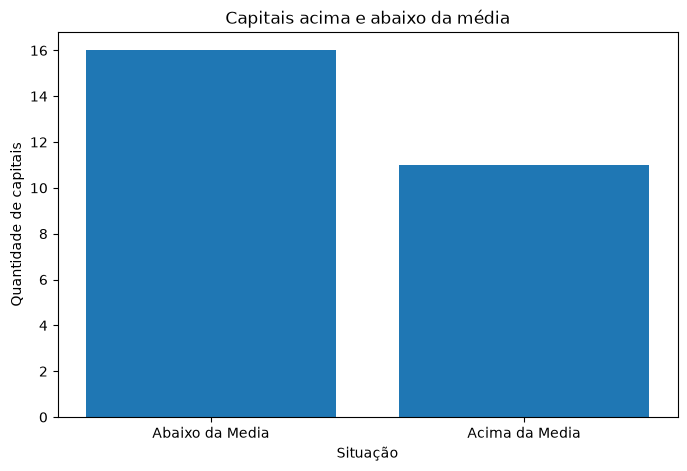

In [43]:
contagem_situacao = df_final["Situacao"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    contagem_situacao.index,
    contagem_situacao.values
)

plt.xlabel("Situação")
plt.ylabel("Quantidade de capitais")
plt.title("Capitais acima e abaixo da média")

plt.show()

### Capitais mais distantes da média
A distância da média permite identificar quais capitais apresentam os maiores desvios em relação ao valor médio do indicador.

In [44]:
df_final["Distancia_da_media"] = abs(df_final["Cesta_Sobre_Renda%"] - media_cesta_renda)

In [45]:
df_distancia = df_final.sort_values(by="Distancia_da_media",ascending=False)

In [46]:
display(df_distancia[["Capital", "Cesta_Sobre_Renda%", "Distancia_da_media", "Situacao"]].head(10))

,Capital,Cesta_Sobre_Renda%,Distancia_da_media,Situacao
10,Brasília,15.74,19.437407,Abaixo da Media
17,São Luís,51.63,16.452593,Acima da Media
12,Fortaleza,48.71,13.532593,Acima da Media
13,Belém,46.94,11.762593,Acima da Media
18,Rio Branco,44.98,9.802593,Acima da Media
6,Curitiba,26.72,8.457407,Abaixo da Media
4,Porto Alegre,27.62,7.557407,Abaixo da Media
2,Rio de Janeiro,28.35,6.827407,Abaixo da Media
1,Florianópolis,28.53,6.647407,Abaixo da Media
19,Manaus,41.81,6.632593,Acima da Media


### Capitais mais distantes da média

O gráfico apresenta as capitais que possuem os maiores desvios em relação à média do indicador Cesta sobre Renda.

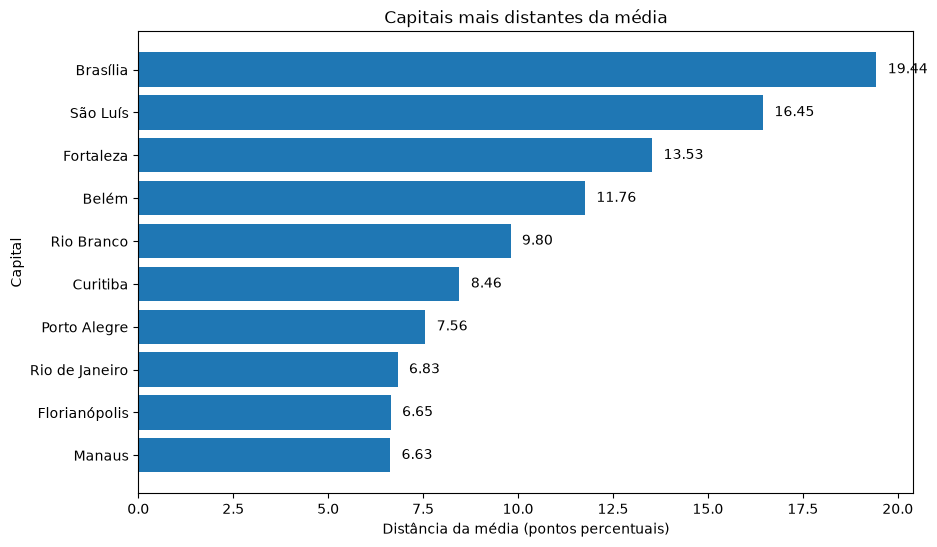

In [47]:
df_grafico_distancia = df_distancia.head(10).sort_values(
    by="Distancia_da_media",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    df_grafico_distancia["Capital"],
    df_grafico_distancia["Distancia_da_media"]
)

plt.xlabel("Distância da média (pontos percentuais)")
plt.ylabel("Capital")
plt.title("Capitais mais distantes da média")

for i, valor in enumerate(df_grafico_distancia["Distancia_da_media"]):
    plt.text(
        valor + 0.3,
        i,
        f"{valor:.2f}",
        va="center"
    )

plt.show()

### Principais observações

A média do indicador Cesta sobre Renda foi de 35,18%.

Das 27 capitais analisadas, 11 apresentaram valores acima da média e 16 ficaram abaixo da média.

Brasília apresentou o maior afastamento da média, com 19,44 pontos percentuais abaixo dela. Já São Luís apresentou o maior afastamento acima da média, com 16,45 pontos percentuais.

Os resultados mostram diferenças relevantes entre as capitais quanto à relação entre o valor da cesta básica e a renda domiciliar per capita.

## Limitações da análise

Os dados de renda utilizados estão disponíveis por Unidade da Federação, enquanto os dados da cesta básica correspondem às capitais. Portanto, a comparação representa uma relação entre a renda domiciliar per capita da UF e o valor da cesta básica observado em sua capital.

Além disso, a cesta básica é apenas um dos componentes das despesas de uma família. O indicador utilizado não representa o custo de vida completo de cada capital, pois não considera outras despesas, como moradia, transporte, saúde, educação e lazer.

Dessa forma, os resultados devem ser interpretados como uma análise exploratória da relação entre renda e custo da cesta básica, e não como um ranking definitivo de custo de vida.

## Capitais com maior e menor comprometimento da renda
A comparação permite identificar as capitais em que o valor da cesta básica representa a maior e a menor parcela da renda domiciliar per capita.

In [48]:
df_final.sort_values(by="Cesta_Sobre_Renda%",ascending=False)[["Capital", "Cesta_Sobre_Renda%", "Situacao"]].head(5)

,Capital,Cesta_Sobre_Renda%,Situacao
17,São Luís,51.63,Acima da Media
12,Fortaleza,48.71,Acima da Media
13,Belém,46.94,Acima da Media
18,Rio Branco,44.98,Acima da Media
19,Manaus,41.81,Acima da Media


In [49]:
df_final.sort_values(by="Cesta_Sobre_Renda%",ascending=True)[["Capital", "Cesta_Sobre_Renda%", "Situacao"]].head(5)

,Capital,Cesta_Sobre_Renda%,Situacao
10,Brasília,15.74,Abaixo da Media
6,Curitiba,26.72,Abaixo da Media
4,Porto Alegre,27.62,Abaixo da Media
2,Rio de Janeiro,28.35,Abaixo da Media
1,Florianópolis,28.53,Abaixo da Media


## Conclusão

A renda utilizada na análise está relacionada às Unidades da Federação, enquanto os dados da cesta básica correspondem às capitais. O que mais chamou minha atenção foram os valores das cestas básicas, principalmente em São Paulo, Florianópolis, Rio de Janeiro e Cuiabá, que apresentaram alguns dos maiores valores.

A média do indicador foi de **35,18%**, representando a parcela média da renda domiciliar per capita correspondente ao valor da cesta básica. A análise mostra quais capitais estão acima ou abaixo dessa média, mas não permite afirmar que uma cidade possui um custo de vida maior ou menor que outra.

Para uma análise mais completa do custo de vida, seria necessário considerar outros fatores, como **aluguel, transporte, saúde e educação**, entre outras despesas.